In [1]:
import math
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
from pathlib import Path
import pandas as pd

df = pd.read_csv(filepath_or_buffer=(Path.cwd().parents[1] / "fraudTrain.csv"),
                index_col=0)
df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])

In [3]:
df.columns

Index(['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt',
       'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat',
       'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat',
       'merch_long', 'is_fraud'],
      dtype='str')

In [4]:
df = df[df['trans_date_trans_time'] < pd.to_datetime("2020-01-01")]
print(df.is_fraud.value_counts() / df.shape[0])
print(df.shape)

is_fraud
0    0.994356
1    0.005644
Name: count, dtype: float64
(924850, 22)


In [5]:
print(df.merchant.nunique()) # merchants
print(df.cc_num.nunique()) # cards
print(len(df)) # transactions

693
960
924850


In [ ]:
def build_graph_bipartite(df_input, graph_type=nx.Graph()):
    df = df_input.copy()
    # {cc_num_or_merchant: enumeration_id}
    # enumeration_id becomes the node id
    mapping = {x:node_id for node_id,x in enumerate(set(df["cc_num"].values.tolist() + df["merchant"].values.tolist()))}
    df["from"] = df["cc_num"].apply(lambda x: mapping[x])
    df["to"] = df["merchant"].apply(lambda x: mapping[x])
    df = df[['from', 'to', "amt", "is_fraud"]].groupby(['from', 'to']).agg({"is_fraud": "sum", "amt": "sum"}).reset_index()
    df["is_fraud"] = df["is_fraud"].apply(lambda x: 1 if x>0 else 0)

    name = graph_type.name
    
    G = nx.from_edgelist(df[["from", "to"]].values, create_using=graph_type)

    G.name = name

    # dictionary of edge tuple to value 
    
    # set bipartite attributes
    nx.set_node_attributes(G,{x:1 for x in df["from"].unique()}, "bipartite")
    nx.set_node_attributes(G,{x:2 for x in df["to"].unique()}, "bipartite")
    
    # set node attributes label, amt
    nx.set_edge_attributes(G, 
                       {(int(x["from"]), int(x["to"])):x["is_fraud"] for idx, x in df[["from","to","is_fraud"]].iterrows()}, 
                       "label")

    nx.set_edge_attributes(G, 
                       {(int(x["from"]), int(x["to"])):x["amt"] for idx, x in df[["from","to","amt"]].iterrows()}, 
                       "weight")
    return G

In [ ]:
def build_graph_tripartite(df_input, graph_type=nx.Graph()):
    df = df_input.copy()
    # {cc_num_or_merchant: enumeration_id}
    # enumeration_id becomes the node id
    mapping = {x:node_id for node_id,x in enumerate(set(df.index.values.tolist() + 
                                                        df["cc_num"].values.tolist() + 
                                                        df["merchant"].values.tolist()))}
    df["in_node"] = df["cc_num"].apply(lambda x: mapping[x])
    df["out_node"] = df["merchant"].apply(lambda x: mapping[x])

    name = graph_type.name
    
    G = nx.from_edgelist([(x["in_node"], mapping[idx]) for idx, x in df.iterrows()] +
                         [(x["out_node"], mapping[idx]) for idx, x in df.iterrows()], 
                         create_using=graph_type)

    G.name = name

    # Set tripartite attributes
    nx.set_node_attributes(G,{x["in_node"]:1 for idx,x in df.iterrows()}, "bipartite")
    nx.set_node_attributes(G,{x["out_node"]:2 for idx,x in df.iterrows()}, "bipartite")
    nx.set_node_attributes(G,{mapping[idx]:3 for idx, x in df.iterrows()}, "bipartite")

    # set node attributes label, amt
    nx.set_edge_attributes(G,{(x["in_node"], mapping[idx]):x["is_fraud"] for idx, x in df.iterrows()}, "label")
    nx.set_edge_attributes(G,{(x["out_node"], mapping[idx]):x["is_fraud"] for idx, x in df.iterrows()}, "label")

    nx.set_edge_attributes(G,{(x["in_node"], mapping[idx]):x["amt"] for idx, x in df.iterrows()}, "weight")
    nx.set_edge_attributes(G,{(x["out_node"], mapping[idx]):x["amt"] for idx, x in df.iterrows()}, "weight")
    return G

In [8]:
G_b = build_graph_bipartite(df, nx.Graph(name="Bipartite Undirect"))

In [9]:
G_t = build_graph_tripartite(df, nx.Graph(name="Tripartite Undirect"))

In [73]:
from networkx.algorithms import bipartite
bipartite.is_bipartite(G_b) 

True

In [42]:
for G in [G_b, G_t]:
    num_fraud_edges = sum(
        1 for u, v, data in G.edges(data=True)
        if data.get('label') == 1
    )
    print(f"Num fraud edges in graph {G.name}")
    print(num_fraud_edges)

Num fraud edges in graph Bipartite Undirect
5131
Num fraud edges in graph Tripartite Undirect
10440


## Network Exploratory analysis

In [10]:
np.set_printoptions(formatter={'float': lambda x: "{0:0.2f}".format(x)})

In [11]:
def network_info(G):
    print(f"Graph name: {G.name}")
    print(f"Number of nodes: {G.number_of_nodes()}")
    print(f"Number of edges: {G.number_of_edges()}")

    # Calculate average degree
    avg_degree = sum(d for n, d in G.degree()) / G.number_of_nodes()
    print(f"Average degree: {avg_degree:.4f}")

for G in (G_b, G_t):
    network_info(G)

Graph name: Bipartite Undirect
Number of nodes: 1653
Number of edges: 422221
Average degree: 510.8542
Graph name: Tripartite Undirect
Number of nodes: 926503
Number of edges: 1849700
Average degree: 3.9929


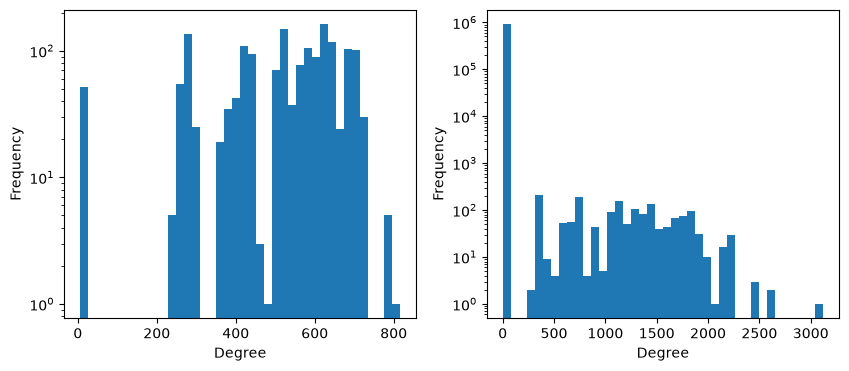

In [86]:
plt.figure(figsize=(10,4))
for ith, G in enumerate([G_b, G_t]):
    plt.subplot(1,2,ith+1)
    degrees = pd.Series({k: v for k, v in nx.degree(G)})
    degrees.plot.hist(bins=40)
    plt.yscale("log")
    plt.xlabel("Degree")

In [84]:
quant_dist = {}

for ith, G in enumerate([G_b, G_t]):
    allEdgesWeights = pd.Series({(d[0], d[1]): d[2]["weight"] for d in G.edges(data=True)})

    quant_dist[G.name] = np.quantile(allEdgesWeights.values,[0.10,0.30,0.50,0.70,0.9,1.0]) 
    print(quant_dist[G.name])

[7.18 38.09 86.47 161.78 352.08 28956.78]
[4.11 15.66 47.40 74.95 136.44 28948.90]


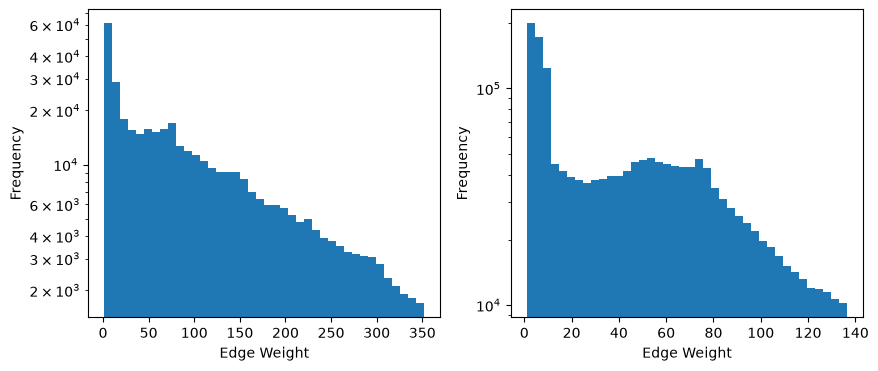

In [87]:
plt.figure(figsize=(10,4))

for ith, G in enumerate([G_b, G_t]):
    plt.subplot(1,2,ith+1)
    allEdgesWeightsFiltered = pd.Series({(d[0], d[1]): d[2]["weight"] for d in G.edges(data=True) 
                                         if d[2]["weight"] < quant_dist[G.name][-2]})
    allEdgesWeightsFiltered.plot.hist(bins=40)
    plt.yscale("log")
    plt.xlabel("Edge Weight")

## Community detection of suspicious networks

In [106]:
import community
import igraph as ig
import leidenalg as la

default_edge_color = 'gray'
default_node_color = '#407cc9'
enhanced_node_color = '#f5b042'
enhanced_edge_color = '#cc2f04'

In [ ]:
def leiden_partition(G):
    # Preserve the original NetworkX node IDs
    nodes = list(G.nodes())

    # Create a mapping between NetworkX IDs and igraph indices
    node_to_idx = {node: idx for idx, node in enumerate(nodes)}

    # Convert edges
    nx_edges = list(G.edges())

    edges = [
        (node_to_idx[u], node_to_idx[v])
        for u, v in nx_edges
    ]

    # Create igraph graph
    G_ig = ig.Graph(
        n=len(nodes),
        edges=edges,
        directed=False
    )

    # Transfer edge weights BEFORE running Leiden
    G_ig.es["weight"] = [
        G[u][v]["weight"]
        for u, v in nx_edges
    ]

    # Run Leiden community detection
    partition = la.find_partition(
        G_ig,
        la.ModularityVertexPartition,
        weights="weight",
        seed=1,
        n_iterations=-1
    )

    # Convert results into dictionary
    leiden_parts = {
        node: int(np.int64(community_id))
        for node, community_id in zip(nodes, partition.membership)
    }

    return leiden_parts

### Bipartite graph

In [115]:
# dictionary of Id: community
louvain_parts_b = community.best_partition(G_b, random_state=1, weight='weight')

In [174]:
leiden_parts_b = leiden_partition(G_b)

In [182]:
def analyze_communities(G, parts):

    print("Number of communities: " + str(len(set(parts.values()))))

    communities = pd.Series(parts)
    print(communities.value_counts().sort_values(ascending=False).head(15))

    communities.value_counts().plot.hist(bins=40)
    plt.xlabel("Community size")

    community_graphs = {}
    d = {}

    for x in communities.unique():
        tmp = nx.subgraph(G, communities[communities == x].index).copy()

        fraud_edges = sum(
            nx.get_edge_attributes(tmp, "label").values()
        )

        ratio = (
            0 if tmp.number_of_edges() == 0
            else (fraud_edges / tmp.number_of_edges()) * 100
        )

        d[x] = ratio
        community_graphs[x] = tmp

    community_fraud_sorted = (
        pd.Series(d).sort_values(ascending=False).head(15)
    )

    print("Community fraud edge percentage")
    print(community_fraud_sorted)

    group_id = community_fraud_sorted.index[0]

    plt.figure(figsize=(10, 10))

    selected_graph = community_graphs[group_id]
    spring_pos = nx.spring_layout(selected_graph)

    plt.axis("off")

    edge_colors = [
        "#FF0000" if x == 1 else "#90EE90"
        for x in nx.get_edge_attributes(selected_graph, "label").values()
    ]

    nx.draw_networkx(
        selected_graph,
        pos=spring_pos,
        node_color=default_node_color,
        edge_color=edge_colors,
        with_labels=False,
        node_size=15,
    )

    plt.title(f"Graph: {G.name} ===> Community: {group_id}")

    plt.show()

Number of communities: 9
3    619
0    385
1    313
2    274
5     19
4     16
8     10
7     10
6      7
Name: count, dtype: int64
Community fraud edge percentage
7    46.153846
8    25.000000
5    11.111111
0     2.903795
4     2.857143
2     2.545487
1     0.978512
3     0.477791
6     0.000000
dtype: float64


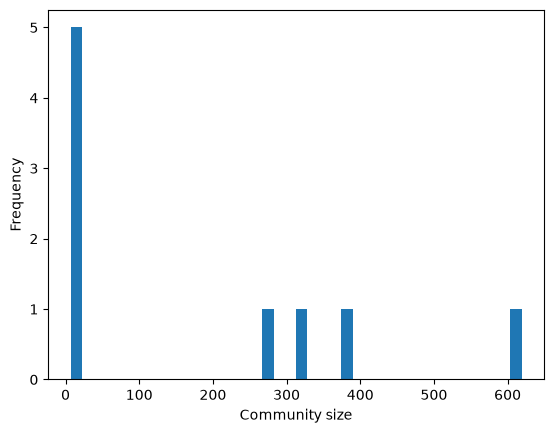

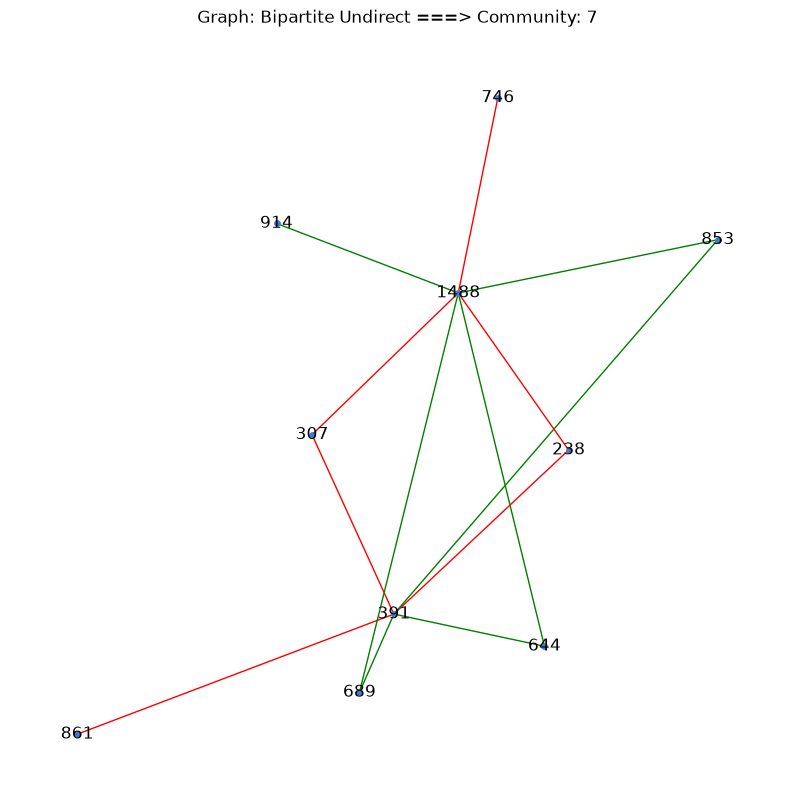

In [154]:
analyze_communities(G_b, louvain_parts_b)

Number of communities: 7
0    661
1    402
2    271
3    261
4     30
5     14
6     14
Name: count, dtype: int64
Community fraud edge percentage
5    20.000000
6    15.384615
4     6.306306
3     3.314578
1     3.087457
2     0.669470
0     0.474684
dtype: float64


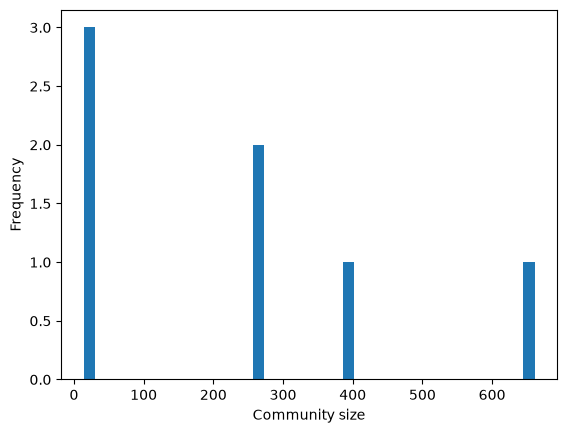

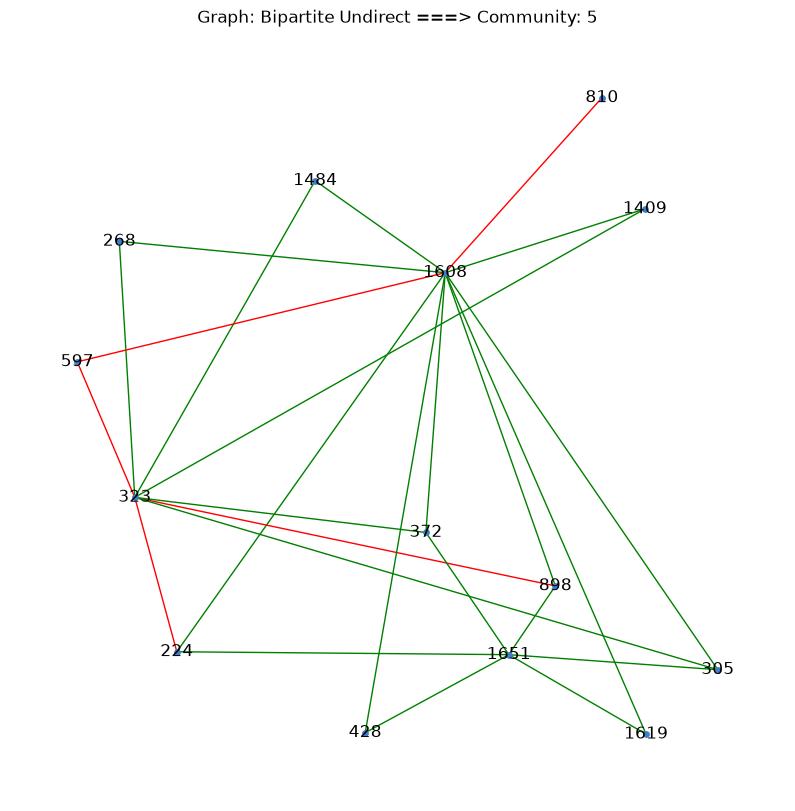

In [175]:
analyze_communities(G_b, leiden_parts_b)

### Tripartite graph

In [176]:
louvain_parts_t = community.best_partition(G_t, random_state=1, weight='weight')

In [177]:
leiden_parts_t = leiden_partition(G_t)

Number of communities: 166
0      29484
70     10640
39     10634
97     10627
92     10213
21      9873
117     9840
83      9792
89      9728
157     9692
71      9543
37      9533
2       9358
13      9182
116     8956
Name: count, dtype: int64
Community fraud edge percentage
36     2.109581
151    1.963351
43     1.703470
127    1.459085
111    1.394484
96     1.268116
119    1.267674
35     1.255432
40     1.211422
56     1.134597
21     1.116984
59     1.116334
4      1.080927
143    1.051136
98     1.044177
dtype: float64


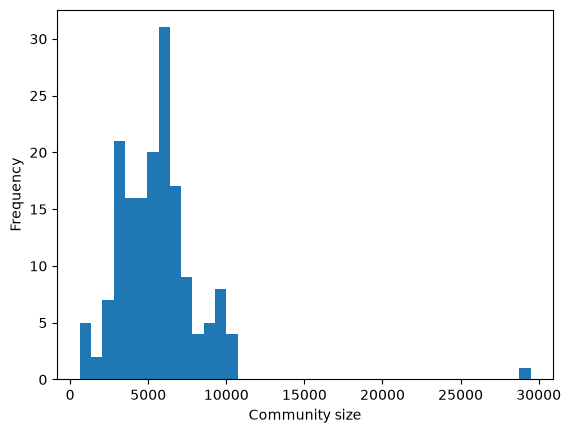

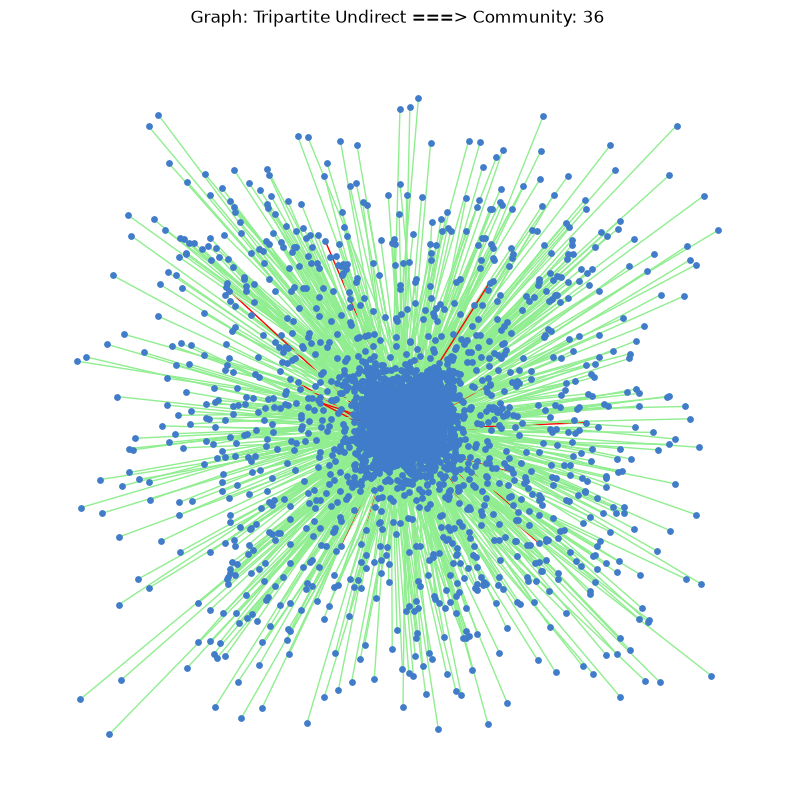

In [183]:
analyze_communities(G_t, louvain_parts_t)

Number of communities: 207
0     26600
1     26369
2     16393
3     10921
4     10441
5      9526
6      8760
7      7760
8      7550
9      7240
10     7184
11     7150
12     7096
13     7051
14     6978
Name: count, dtype: int64
Community fraud edge percentage
47     1.870063
65     1.510010
140    1.379066
101    1.376901
37     1.339426
73     1.300728
26     1.296939
95     1.291193
75     1.278011
86     1.157114
43     1.109146
99     1.091791
58     1.087138
42     1.030438
13     1.028894
dtype: float64


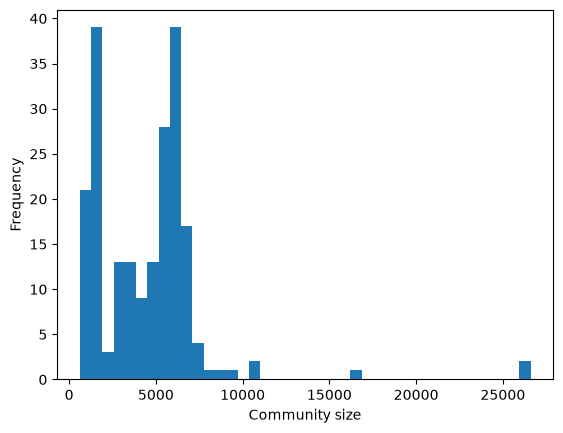

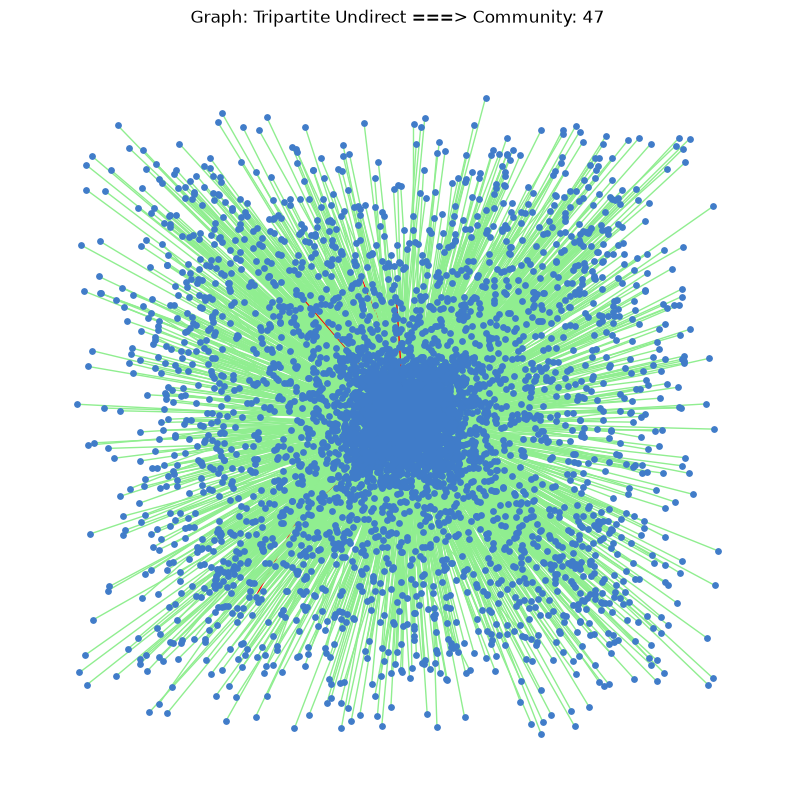

In [184]:
analyze_communities(G_t, leiden_parts_t)